# Fits to the $M_{BH}$ - $M_{\star}$ Scaling Relation

Ragadeepika Pucha, Stéphanie Juneau, Arjun Dey, Mar Mezcua, Yao-Yuan Mao, and others ...

This notebook contains detailed analysis related to BH Mass - Stellar Mass Scaling Relation.

In [1]:
import numpy as np
import pandas as pd

from astropy.table import Table, Column

import sys
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/DESI_Project/py/')
sys.path.append('/global/cfs/cdirs/desi/users/raga19/repos/linmix/linmix/')

import bpt
import utils

import matplotlib.pyplot as plt
from matplotlib.colors import LogNorm

from scipy.ndimage import gaussian_filter
import linmix

In [2]:
## Making the matplotlib plots look nicer
settings = {
    'mathtext.fontset': 'stix',
    'font.family': 'STIXGeneral',
    'font.size':22,
    'axes.labelsize': 'large',
    'lines.markersize': 5,
    'axes.linewidth':3.0,
    'xtick.major.size':7.0,
    'xtick.minor.size':4.0,
    'xtick.major.width':3.0,
    'xtick.minor.width':1.5,
    'xtick.direction':'in', 
    'xtick.minor.visible':True,
    'xtick.top':True,
    'ytick.major.size':7.0,
    'ytick.minor.size':4.0,
    'ytick.major.width':3.0,
    'ytick.minor.width':1.5,
    'ytick.direction':'in', 
    'ytick.minor.visible':True,
    'ytick.right':True,
    'contour.linewidth':3.0,
    'savefig.bbox': 'tight',
    'savefig.dpi': 200,
}

plt.rcParams.update(**settings)

In [3]:
## Read in the BL-AGN Candidates
t = Table.read('../catalogs/iron-blagn-selection.fits')

In [4]:
## Stellar Mass and Black Hole Mass

logmass = t['LOGM'].data
logmass_err = t['LOGM_ERR'].data

bh_mass = t['LOG_MBH'].data
bh_mass_err = t['LOG_MBH_ERR'].data

vi_flag = t['VI_FLAG'].data

z = t['Z'].data
mbh_mstar = np.log10((10**bh_mass)/(10**logmass))

In [5]:
## Morphology related variables
mtype = t['TYPE'].astype(str).data
ser = t['SERSIC'].data

is_psf = mtype == 'PSF'
is_late = ((mtype == 'REX')|(mtype == 'EXP')|((mtype == 'SER')&(ser <= 2)))
is_early = ~is_psf & ~is_late

In [6]:
## Bolometric Luminosity and Eddington Ratio

log_Lbol = t['LOG_LBOL'].data
log_lamedd = t['LOG_EDD_RATIO'].data

In [7]:
## Other Variables

lomass = (logmass <= 9.5)
himass = (logmass > 9.5)

ha_b_fwhm = utils.sigma_to_fwhm(t['HA_B_SIGMA'].data)
is_def = (t['NII_HA_SII_NDOF'].data == 0)&(t['HB_OIII_NDOF'].data == 0)
is_ebl = (t['HB_NDOF'].data == 0)&(t['OIII_NDOF'].data == 0)&(t['NII_HA_NDOF'].data == 0)&(t['SII_NDOF'].data == 0)

vi0 = (vi_flag == 0)
vi1 = (vi_flag == 1)

is_imbh = (bh_mass <= 6)

In [8]:
print ('Number of log MBH <= 6 Candidates:', len(t[is_imbh&(vi0|vi1)]))
print ('Number of log MBH <= 5 Candidates:', len(t[(bh_mass <= 5)&(vi0|vi1)]))

Number of log MBH <= 6 Candidates: 792
Number of log MBH <= 5 Candidates: 50


In [9]:
print ('Total Number of Extended BL-AGN Candidates: ', len(t[~is_psf]))
print ('Number of Regular BL-AGN Candidates:', len(t[is_def&~is_psf]))
print ('Number of EBL-AGN Candidates: ', len(t[is_ebl&~is_psf]))

Total Number of Extended BL-AGN Candidates:  15871
Number of Regular BL-AGN Candidates: 11863
Number of EBL-AGN Candidates:  4008


In [10]:
print ('Median FWHM of Regular BL-AGN Candidates: ', np.median(ha_b_fwhm[is_def&~is_psf]))
print ('Median FWHM of EBL-AGN Candidates: ', np.median(ha_b_fwhm[is_ebl&~is_psf]))

Median FWHM of Regular BL-AGN Candidates:  1976.976985645031
Median FWHM of EBL-AGN Candidates:  4706.320332802519


In [11]:
print ('Minimum, Maximum, Median, log Lbol', min(log_Lbol[~is_psf]), max(log_Lbol[~is_psf]), np.median(log_Lbol[~is_psf]))

print ('Minimum, Maximum, Median, log Edd Ratio', min(10**log_lamedd[~is_psf]), max(10**log_lamedd[~is_psf]), np.median(10**log_lamedd[~is_psf]))

Minimum, Maximum, Median, log Lbol 41.08184907571593 46.37811459071511 44.14833371816003
Minimum, Maximum, Median, log Edd Ratio 0.00020122219205273074 29.47405315657483 0.059326414154933914


In [12]:
print ('Regular BL-AGN: Minimum, Maximum, Median, log Lbol', min(log_Lbol[~is_psf&is_def]), max(log_Lbol[~is_psf&is_def]), np.median(log_Lbol[~is_psf&is_def]))
print ('Regular BL-AGN: Minimum, Maximum, Median, log Edd Ratio', min(10**log_lamedd[~is_psf&is_def]), max(10**log_lamedd[~is_psf&is_def]), np.median(10**log_lamedd[~is_psf&is_def]))

Regular BL-AGN: Minimum, Maximum, Median, log Lbol 41.08184907571593 46.1924242498821 44.05033231400917
Regular BL-AGN: Minimum, Maximum, Median, log Edd Ratio 0.0004962676050292227 29.47405315657483 0.08504097518914659


In [13]:
print ('Extreme BL-AGN: Minimum, Maximum, Median, log Lbol', min(log_Lbol[~is_psf&is_ebl]), max(log_Lbol[~is_psf&is_ebl]), np.median(log_Lbol[~is_psf&is_ebl]))
print ('Regular BL-AGN: Minimum, Maximum, Median, log Edd Ratio', min(10**log_lamedd[~is_psf&is_ebl]), max(10**log_lamedd[~is_psf&is_ebl]), np.median(10**log_lamedd[~is_psf&is_ebl]))

Extreme BL-AGN: Minimum, Maximum, Median, log Lbol 41.97487091890166 46.37811459071511 44.442509090206286
Regular BL-AGN: Minimum, Maximum, Median, log Edd Ratio 0.00020122219205273074 1.2240398797121332 0.018960806173793254


### Overmassive BHs from Literature

In [14]:
## Overmeassive Black Holes from z~0.35 to z~7

## VIPERS Lowz
vipers_lowz = pd.read_csv('../catalogs/other_cats/Mezcua2023.txt', header = 0, sep=r"[,\t]+")
## Put all -- to nans
vipers_lowz = vipers_lowz.replace('--', np.nan)

## VIPERS High-z
vipers_highz = pd.read_csv('../catalogs/other_cats/Mezcua2024.txt', header = 0, sep=r"[,\t]+")
## Put all -- to nans
vipers_highz = vipers_highz.replace('--', np.nan)
vipers_highz['logBHmass'] = vipers_highz['logBHmass'].astype(np.float16)
vipers_highz['logBHmass_err'] = vipers_highz['logBHmass_err'].astype(np.float16)

## JWST compilation 
## Used in Pacucci+2023 fit
jwst_p23 = pd.read_csv('../catalogs/other_cats/JWST_Pacucci.txt', header = 0, sep=r"[,\t]+", comment = '%')
#Add arrows for upper limits on stellar mass
jwst_uplim_p23 = (jwst_p23['logMstar_eu']==-99.00)
jwst_mstar_uplimit_p23 = jwst_p23[jwst_uplim_p23]

## Other Studies
jwst_oth = pd.read_csv('../catalogs/other_cats/JWST_dataALL.txt', header = 0, sep=r"[,\t]+", comment = '%')
#Add arrows for upper limits on stellar mass
jwst_uplim_oth = (jwst_oth['logMstar_eu']==-99.00)
jwst_mstar_uplimit_oth = jwst_oth[jwst_uplim_oth]

In [15]:
def overplot_highz_points(axs = None, size = 50, label = True):

    if (axs == None):
        axs = plt.gca()

    if (label == True):
        ## VIPERS Low-z (Mezcua et al. 2023)
        axs.scatter(vipers_lowz['logMstellar'],vipers_lowz['logBHmass'],s=size, edgecolor='k', marker='s', color='gold', label='Mezcua+2023, z$\sim$0.4 $-$ 0.9', zorder = 3)
    else:
        ## VIPERS Low-z (Mezcua et al. 2023)
        axs.scatter(vipers_lowz['logMstellar'],vipers_lowz['logBHmass'],s=size, edgecolor='k', marker='s', color='gold', zorder = 3)
    #Plot error bars
    xerr=[np.abs(vipers_lowz['logMstellar_lerr']),vipers_lowz['logMstellar_uerr']]
    yerr = [vipers_lowz['logBHmass_err'], vipers_lowz['logBHmass_err']]
    axs.errorbar(vipers_lowz['Ms(best)'], vipers_lowz['logBHmass'], yerr=yerr, xerr=xerr, fmt='none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## VIPERS High-z (Mezcua et al. 2024)
        axs.scatter(vipers_highz['logMstellar'],vipers_highz['logBHmass'],s=size+20, edgecolor='k', marker='o', color='lime', label='Mezcua+2024, z$\sim$1 $-$ 3', zorder = 3)
    else:
        ## VIPERS High-z (Mezcua et al. 2024)
        axs.scatter(vipers_highz['logMstellar'],vipers_highz['logBHmass'],s=size+20, edgecolor='k', marker='o', color='lime', zorder = 3)
    #Plot error bars
    xerr=[np.abs(vipers_highz['logMstellar_lerr']),vipers_highz['logMstellar_uerr']]
    yerr = [vipers_highz['logBHmass_err'], vipers_highz['logBHmass_err']]
    axs.errorbar(vipers_highz['Ms(best)'], vipers_highz['logBHmass'], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## JWST Used in Paccucci+2023 fit
        axs.scatter(jwst_p23['logMstar'], jwst_p23['logMbh'], s=size, edgecolor='k', marker='D', color='m', label='JWST, z$\sim$4 $-$ 8', zorder = 2)
    else:
        ## JWST Used in Paccucci+2023 fit
        axs.scatter(jwst_p23['logMstar'], jwst_p23['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    axs.scatter(jwst_mstar_uplimit_p23['logMstar']-0.07, jwst_mstar_uplimit_p23['logMbh']-0.01, s=3*size, edgecolor='k', marker=r'$\leftarrow$', alpha = 0.3, zorder = 3)
    #Plot error bars
    xerr = [jwst_p23['logMstar_el'][~jwst_uplim_p23],jwst_p23['logMstar_eu'][~jwst_uplim_p23]]
    yerr = [jwst_p23['logMbh_el'][~jwst_uplim_p23], jwst_p23['logMbh_eu'][~jwst_uplim_p23]]
    axs.errorbar(jwst_p23['logMstar'][~jwst_uplim_p23], jwst_p23['logMbh'][~jwst_uplim_p23], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

    if (label == True):
        ## JWST Others
        axs.scatter(jwst_oth['logMstar'], jwst_oth['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    else:
        ## JWST Others
        axs.scatter(jwst_oth['logMstar'], jwst_oth['logMbh'], s=size, edgecolor='k', marker='D', color='m', zorder = 2)
    axs.scatter(jwst_mstar_uplimit_oth['logMstar']-0.07, jwst_mstar_uplimit_oth['logMbh']-0.01, s=3*size, edgecolor='k', marker=r'$\leftarrow$', alpha = 0.3, zorder = 3)
    #Plot error bars
    xerr = [jwst_oth['logMstar_el'][~jwst_uplim_oth], jwst_oth['logMstar_eu'][~jwst_uplim_oth]]
    yerr = [jwst_oth['logMbh_el'][~jwst_uplim_oth], jwst_oth['logMbh_eu'][~jwst_uplim_oth]]
    axs.errorbar(jwst_oth['logMstar'][~jwst_uplim_oth], jwst_oth['logMbh'][~jwst_uplim_oth], yerr, xerr, 'none', alpha = 0.3, color='k', ecolor='k')

### Fit Related Functions and Variables

In [16]:
def mstar_to_bh(mass, a, b):
    term1 = b*np.log10(mass/1e+11)
    yy = a + term1
    
    return (yy)

In [17]:
def mstar_mbh_p23(mass):
    term1 = 1.06*np.log10(mass)
    log_mbh = -2.43 + term1

    return (log_mbh)

In [18]:
def mstar_mbh_suh2020(mass):
    term1 = 1.64*np.log10(mass)
    term2 = -10.29
    
    mbh = term1 + term2
    
    return (mbh)

In [19]:
def mstar_mbh_greene2020(mass, a = 7.56, b = 1.39, e = 0.79):
    term1 = a
    term2 = b*np.log10(mass/3e+10)

    mbh = term1 + term2

    return (mbh)

In [20]:
def mbh_mstar_lines(mstar, m):
    mbh = m*mstar
    return (mbh)

In [21]:
mass_xx = np.logspace(6, 13, 1000)
mbh_early = mstar_to_bh(mass_xx, a = 8.95, b = 1.40)
mbh_late = mstar_to_bh(mass_xx, a = 7.45, b = 1.05)
mbh_p25 = mstar_to_bh(mass_xx, a = 7.66, b = 1.15)
mbh_p23 = mstar_mbh_p23(mass_xx)
mbh_g20 = mstar_mbh_greene2020(mass_xx, a = 7.43, b = 1.61, e = 0.81)
mbh_suh2020 = mstar_mbh_suh2020(mass_xx)

In [22]:
def add_literature_fits(axs = None, pucha25 = True, pacucci23 = True, greene20 = True, suh20 = True,\
                        r13_late = True, r13_early = True, linewidth = 3.0, label = False):

    if (axs == None):
        axs = plt.gca()

    if (label == False):
        jwst_kwargs = {'color' : 'm', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 2}
        p25_kwargs = {'color' : 'k', 'linestyle' : '-.', 'linewidth' : linewidth+0.5, 'zorder' : 2}
        r13_late_kwargs = {'color' : 'dimgray', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 1}
        r13_early_kwargs = {'color': 'dimgray', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 1}
        g20_kwargs = {'color': '#ffac3b', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 2}
        suh_kwargs = {'color': 'goldenrod', 'linestyle' : '-', 'linewidth' : linewidth, 'zorder' : 2}
    else:
        jwst_kwargs = {'color' : 'm', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Pacucci+2023'}
        p25_kwargs = {'color' : 'k', 'linestyle' : '-.', 'linewidth' : linewidth+0.5, 'zorder' : 2, 'label' : 'Pucha+2025'}
        r13_late_kwargs = {'color' : 'dimgray', 'linestyle' : '--', 'linewidth' : linewidth, 'zorder' : 1, 'label' : 'Reines+2015'}
        r13_early_kwargs = {'color': 'dimgray', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 1, 'label' : 'Reines+2015 (Early)'}
        g20_kwargs = {'color': '#ffac3b', 'linestyle' : ':', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Greene+2020'}
        suh_kwargs = {'color': 'goldenrod', 'linestyle' : '-', 'linewidth' : linewidth, 'zorder' : 2, 'label' : 'Suh+2020'}

    if (pucha25 == True):
        axs.plot(np.log10(mass_xx), mbh_p25, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_p25, **p25_kwargs)
        
    if (pacucci23 == True):
        axs.plot(np.log10(mass_xx), mbh_p23, color = 'white', lw = linewidth, zorder = 2)
        axs.plot(np.log10(mass_xx), mbh_p23, **jwst_kwargs)

    if (greene20 == True):
        axs.plot(np.log10(mass_xx), mbh_g20, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_g20, **g20_kwargs)

    if (suh20 == True):
        axs.plot(np.log10(mass_xx), mbh_suh2020, color = 'white', lw = linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_suh2020, **suh_kwargs)

    if (r13_late == True):
        axs.plot(np.log10(mass_xx), mbh_late, color = 'white', lw = 2*linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_late, **r13_late_kwargs)

    if (r13_early == True):
        axs.plot(np.log10(mass_xx), mbh_early, color = 'white', lw = linewidth, zorder = 1)
        axs.plot(np.log10(mass_xx), mbh_early, **r13_early_kwargs)    

### Fits

In [23]:
def linmix_fit(xx, yy, xerr, yerr):
    lm = linmix.LinMix(xx, yy, xsig = xerr, ysig = yerr)
    lm.run_mcmc(miniter = 5000, silent = True)
    
    a = lm.chain['alpha'].mean()
    b = lm.chain['beta'].mean()
    a_err = lm.chain['alpha'].std()
    b_err = lm.chain['beta'].std()
    
    return (a, a_err, b, b_err)

logmass_11 = logmass - 11

In [24]:
# a_ext, aerr_ext, b_ext, berr_ext = linmix_fit(logmass_11[~is_psf], bh_mass[~is_psf], \
#                                              logmass_err[~is_psf], bh_mass_err[~is_psf])

# a_psf, aerr_psf, b_psf, berr_psf = linmix_fit(logmass_11[is_psf], bh_mass[is_psf], \
#                                              logmass_err[is_psf], bh_mass_err[is_psf])

# a_all, aerr_all, b_all, berr_all = linmix_fit(logmass_11, bh_mass, \
#                                              logmass_err, bh_mass_err)

In [25]:
# a_ext, aerr_ext, b_ext, berr_ext

In [26]:
# a_psf, aerr_psf, b_psf, berr_psf

In [27]:
# a_all, aerr_all, b_all, berr_all

In [28]:
a_ext, aerr_ext, b_ext, berr_ext = (7.627269683880347, 0.006563102420785898, 1.019242500318526, 0.012071992317511073)
a_psf, aerr_psf, b_psf, berr_psf = (8.461820747292254, 0.035128579807597496, 1.0330915349989231, 0.03781416049520155)
a_all, aerr_all, b_all, berr_all = (7.655680636813742, 0.00704660366300485, 0.8958283811998237, 0.012244683806455287)

In [29]:
mbh_ext = mstar_to_bh(mass_xx, a = a_ext, b = b_ext)
mbh_psf = mstar_to_bh(mass_xx, a = a_psf, b = b_psf)
mbh_all = mstar_to_bh(mass_xx, a = a_all, b = b_all)

In [30]:
dens1, _, _ = np.histogram2d(logmass[~is_psf], bh_mass[~is_psf], \
                         bins=70, range = [[8, 12.5], [3.8, 10]], density = True)

dens2, _, _ = np.histogram2d(logmass[is_psf], bh_mass[is_psf], \
                        bins=50, range = [[8, 12.5], [3.8, 10]], density = True)

## Apply Gaussian filter to smooth the density arrays
dens1_smooth = gaussian_filter(dens1, sigma = 1.5)
dens2_smooth = gaussian_filter(dens2, sigma = 1.5)

In [31]:
ext_kwargs = {'color' : 'orangered', 'linestyle' : '-', 'zorder' : 3}

In [32]:
## Greene, Strader, and Ho (2020)

logmass_g20 = np.array([10.1, 10.2, 10.2, 10.2, 10.2, 10.3, 10.3, 10.3, 10.4, 10.4, 10.5, 10.5, 10.5, 10.5, 10.5, 10.5, \
                        10.6, 10.6, 10.6, 10.6, 10.6, 10.6, 10.7, 10.7, 10.7, 10.7, 10.7, 10.7, 10.8, 10.8, 10.8, 10.8, \
                        10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.8, 10.9, 10.9, 10.9, 10.9, 10.9, \
                        10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 10.9, 11, 11, 11, 11, 11, 11, \
                        11, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.1, 11.2, 11.2, 11.2, 11.2, 11.2, 11.2, 11.2, 11.3, \
                        11.3, 11.3, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.4, 11.5, 11.5, 11.5, 11.5, 11.5, 11.5, \
                        11.5, 11.5, 11.5, 11.6, 11.6, 11.6, 11.6, 11.6, 11.6, 11.7, 11.7, 11.7, 11.8, 11.8, 11.9])

bhmass_g20 = np.array([7.61, 7.63, 7.16, 7.16, 6.95, 7.85, 7.28, 6.06, 8.69, 8.66, 8.25, 8.26, 7.94, 7.65, 6.77, \
                       6.86, 7.83, 8.77, 8.93, 8.36, 6.83, 6.13, 8.00, 6.85, 8.99, 7.03, 7.88, 7.88, 7.81, 6.40, \
                       7.81, 8.62, 7.95, 7.84, 7.62, 8.38, 6.94, 8.16, 7.81, 7.58, 6.94, 6.88, 6.19, 8.60, 8.11, \
                       6.74, 8.23, 6.93, 8.73, 8.70, 8.67, 8.31, 8.44, 8.22, 7.85, 8.95, 7.88, 7.32, 6.70, 6.98, \
                       8.40, 7.36, 9.23, 7.03, 7.76, 7.20, 7.74, 7.41, 7.89, 8.60, 9.17, 9.32, 10.23, 8.65, 7.30, \
                       8.26, 9.59, 8.93, 8.14, 8.94, 8.52, 9.45, 9.04, 6.92, 8.04, 8.00, 8.85, 8.51, 8.94, 9.57, \
                       7.11, 8.82, 9.57, 8.97, 9.67, 9.68, 9.57, 9.36, 9.39, 8.72, 8.60, 9.67, 9.96, 9.79, 9.13, \
                       9.57, 9.11, 9.11, 10.23, 9.40, 9.86, 8.23, 10.32])

In [33]:
clevels = list(np.logspace(np.log10(0.02), np.log10(0.8), 6))

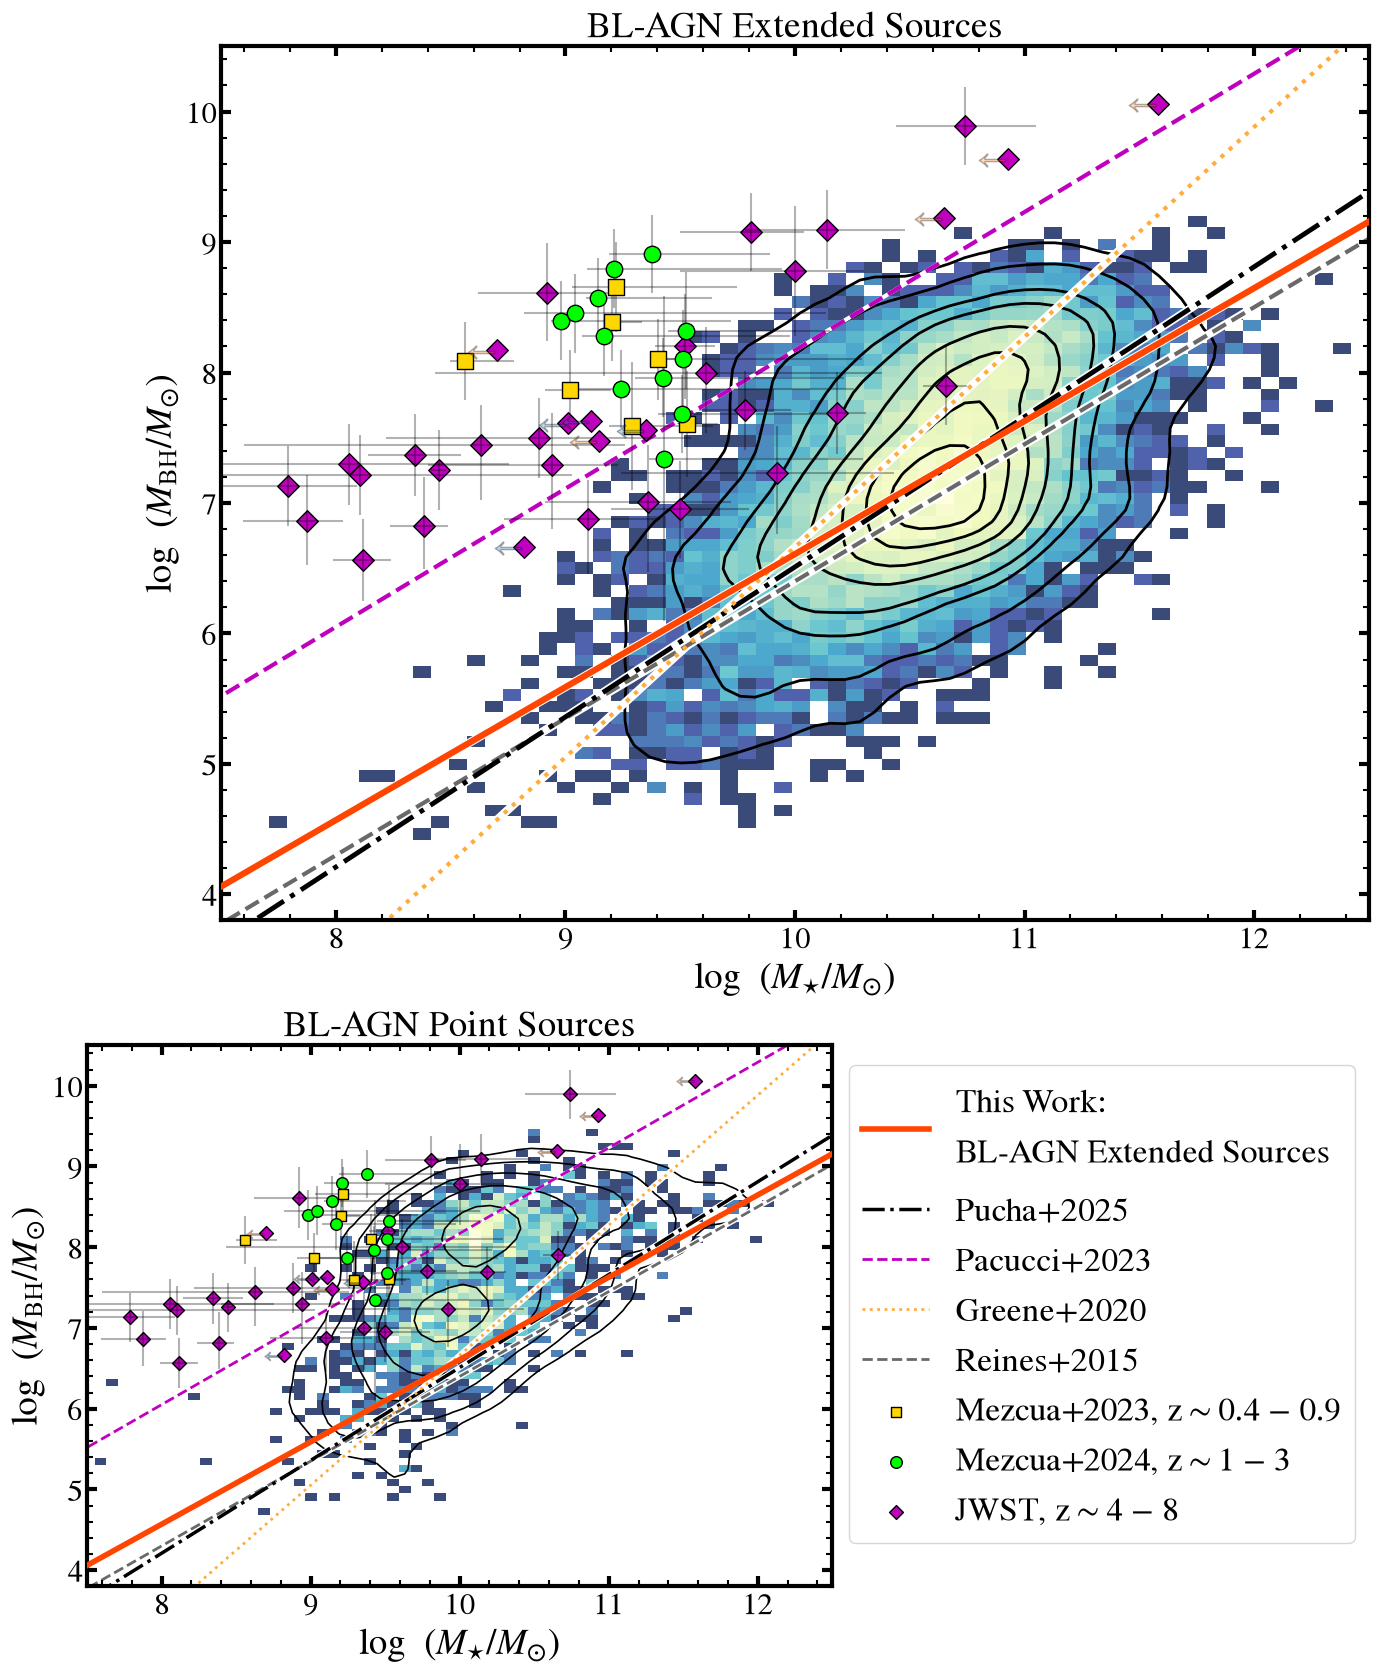

In [34]:
fig = plt.figure(figsize = (20, 20))
grid = plt.GridSpec(5, 12, hspace = 0.6, wspace = 0.8)

ax1 = fig.add_subplot(grid[0:3, 2:11])
ax2 = fig.add_subplot(grid[3:, 1:7])

h1 = ax1.hist2d(logmass[~is_psf], bh_mass[~is_psf], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
ax1.contour(dens1_smooth.T, levels = [0.015, 0.04, 0.1, 0.15, 0.25, 0.35, 0.45, 0.55], \
            extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 2.0, zorder = 1)
ax1.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
ax1.plot(np.log10(mass_xx), mbh_ext, lw = 4.5, **ext_kwargs)
add_literature_fits(axs=ax1, r13_early=False, suh20 = False, label = False)
# ax1.scatter(logmass_g20, bhmass_g20, s = 100, edgecolor = 'k', marker = '^', color = 'orange', label = 'Greene+2020')
overplot_highz_points(size = 120, label = False, axs = ax1)
ax1.set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$',\
              ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$', title = 'BL-AGN Extended Sources')
# leg1 = ax1.legend(loc = 'lower right', fontsize = 24, frameon = True, bbox_to_anchor = (0.84,-0.47))

h2 = ax2.hist2d(logmass[is_psf], bh_mass[is_psf], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
ax2.contour(dens2_smooth.T, levels = clevels, extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 1.2, zorder = 1)
ax2.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 3.5, zorder = 1)
ax2.plot(np.log10(mass_xx), mbh_ext, lw = 4.0, label = 'This Work: \nBL-AGN Extended Sources', **ext_kwargs)
add_literature_fits(axs=ax2, linewidth=2.0, r13_early = False,  suh20 = False, label = True)
# ax2.scatter(logmass_g20, bhmass_g20, s = 100, edgecolor = 'k', marker = '^', color = 'orange', label = 'Greene+2020')
overplot_highz_points(size = 50, label = True, axs = ax2)
ax2.set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$', \
        ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$', title = 'BL-AGN Point Sources')
leg2 = ax2.legend(loc = 'lower left', fontsize = 24, frameon = True, bbox_to_anchor = (1,0.05))

# plt.savefig('mbh-mstar.png', bbox_inches = 'tight')

In [35]:
def get_data_hist2d(h2d):
    xx = np.array([])
    yy = np.array([])
    nn = np.array([])
    
    for ii in range(len(h2d[1])-1):
        for jj in range(len(h2d[2])-1):
            xx = np.append(xx, h2d[1][ii])
            yy = np.append(yy, h2d[2][jj])
            nn = np.append(nn, h2d[0][ii][jj])
            
    return (xx, yy, nn)

In [36]:
# xx1, yy1, nn1 = get_data_hist2d(h1)
# xx2, yy2, nn2 = get_data_hist2d(h2)

# t1 = Table()
# t1['LOGMASS'] = xx1
# t1['LOG_MBH'] = yy1
# t1.add_column(Column(nn1, name = 'NUM', dtype = np.int))
# t1.write('../catalogs/paper_figures/Fig05a_mbh_mstar_extended.csv', overwrite = True)

# t2 = Table()
# t2['LOGMASS'] = xx2
# t2['LOG_MBH'] = yy2
# t2.add_column(Column(nn2, name = 'NUM', dtype = np.int))
# t2.write('../catalogs/paper_figures/Fig05b_mbh_mstar_point.csv', overwrite = True)

### EBL vs. Default Mode Fits

In [37]:
## Extended Default Sources
# a_extd, aerr_extd, b_extd, berr_extd = linmix_fit(logmass_11[~is_psf&is_def], bh_mass[~is_psf&is_def],\
#                                                   logmass_err[~is_psf&is_def], bh_mass_err[~is_psf&is_def])

a_extd, aerr_extd, b_extd, berr_extd = (7.309488506848379, 0.006790046521648044, 0.778119890371959, 0.010800623846220865)

In [38]:
## Extended EBL Sources
# a_exte, aerr_exte, b_exte, berr_exte = linmix_fit(logmass_11[~is_psf&is_ebl], bh_mass[~is_psf&is_ebl], \
#                                                  logmass_err[~is_psf&is_ebl], bh_mass_err[~is_psf&is_ebl])

a_exte, aerr_exte, b_exte, berr_exte = (8.106163857737492, 0.010201484037270793, 0.3809397207434831, 0.01908812963566092)

In [39]:
dens_extd, _, _ = np.histogram2d(logmass[is_def&~is_psf], \
                               bh_mass[is_def&~is_psf], \
                               bins = 70, range = [[8, 12.5], [3.8, 10]], density = True)
dens_exte, _, _ = np.histogram2d(logmass[is_ebl&~is_psf], \
                               bh_mass[is_ebl&~is_psf], \
                               bins = 70, range = [[8, 12.5], [3.8, 10]], density = True)

## Gaussian filter to smooth the density arrays
dens_extd_smooth = gaussian_filter(dens_extd, sigma = 1.5)
dens_exte_smooth = gaussian_filter(dens_exte, sigma = 1.5)

In [40]:
mass_xx1 = np.logspace(6, 9.3, 1000)
mass_xx2 = np.logspace(9.3, 13, 1000)

In [41]:
mbh_extd = mstar_to_bh(mass_xx, a = a_extd, b = b_extd)
mbh_exte1 = mstar_to_bh(mass_xx1, a = a_exte, b = b_exte)
mbh_exte2 = mstar_to_bh(mass_xx2, a = a_exte, b = b_exte)

In [42]:
extd_kwargs = {'color':'#00b408', 'linestyle': '-.', 'zorder':3}
exte_kwargs = {'color':'#00c2f9', 'linestyle': '-.', 'zorder':3}

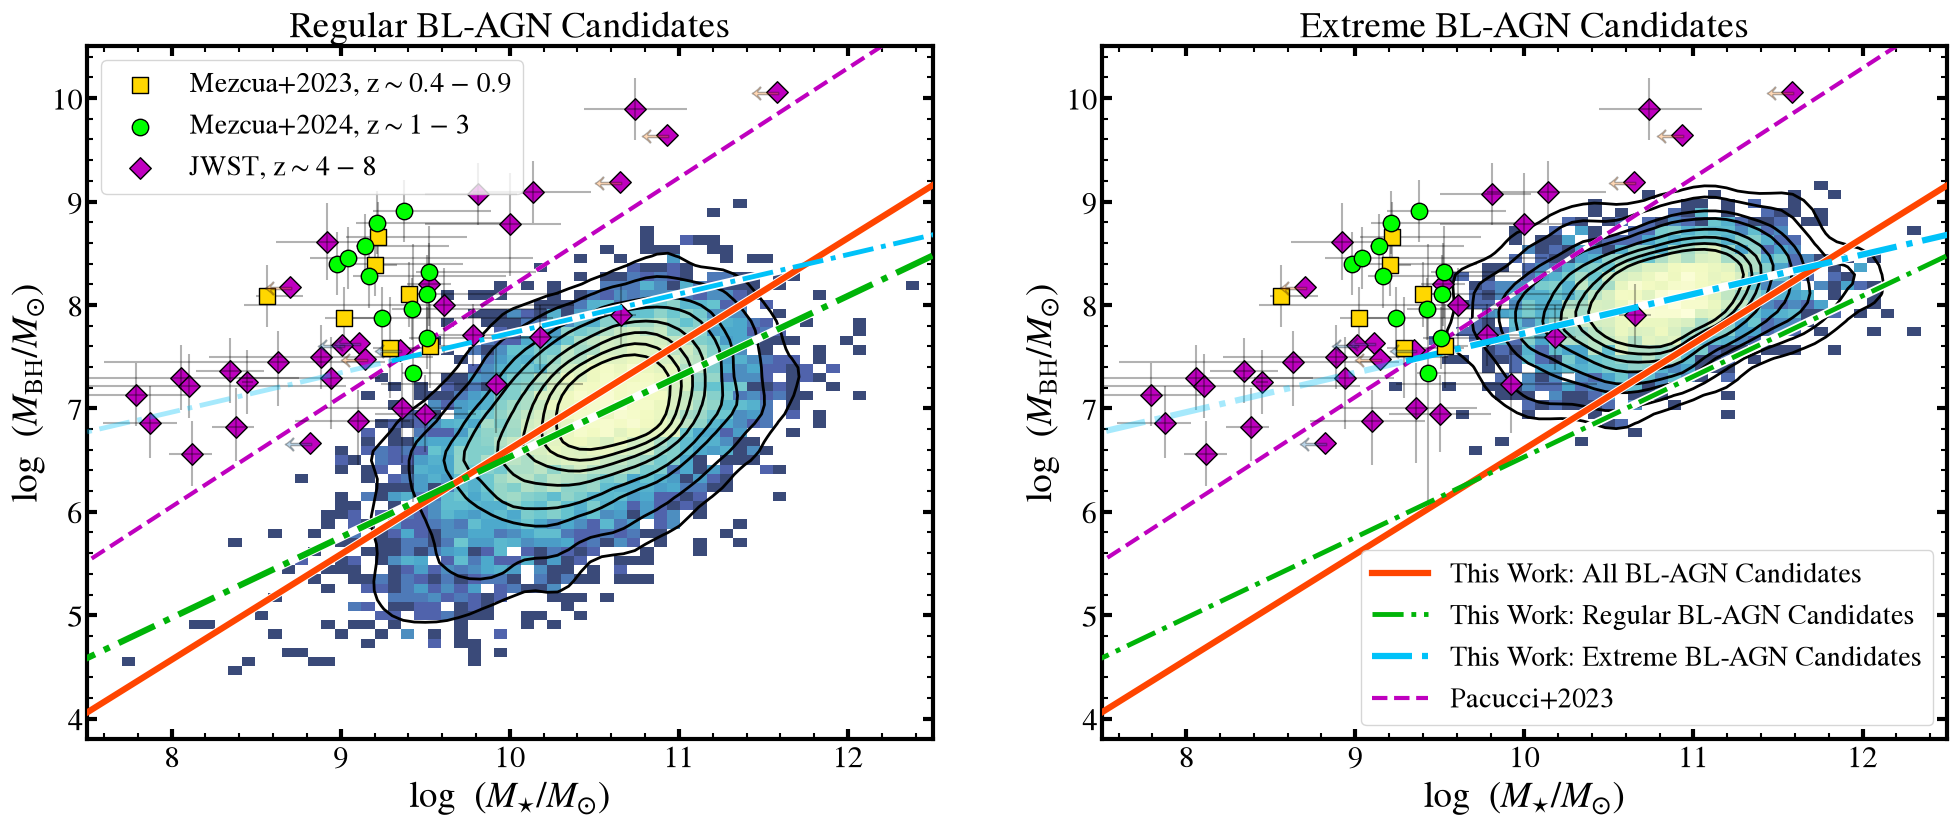

In [43]:
plt.figure(figsize = (24, 9))

plt.subplot2grid((1,2), (0,0))
plt.title('Regular BL-AGN Candidates')
h1 = plt.hist2d(logmass[~is_psf&is_def], bh_mass[~is_psf&is_def], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
plt.contour(dens_extd_smooth.T, levels = [0.015, 0.04, 0.1, 0.15, 0.25, 0.35, 0.45, 0.55], \
            extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 2.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, lw = 4.5, **ext_kwargs)
plt.plot(np.log10(mass_xx), mbh_extd, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_extd, lw = 4.5, **extd_kwargs)
plt.plot(np.log10(mass_xx1), mbh_exte1, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx1), mbh_exte1, alpha = 0.35, lw = 3.5, **exte_kwargs)
plt.plot(np.log10(mass_xx2), mbh_exte2, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx2), mbh_exte2, lw = 3.5, **exte_kwargs)
add_literature_fits(r13_early=False, suh20 = False, r13_late = False, \
                    pucha25 = False, greene20 = False, label = False)
overplot_highz_points(size = 120, label = True)
plt.gca().set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$',\
              ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$')
plt.legend(loc = 'upper left', fontsize = 20)

plt.subplot2grid((1,2), (0,1))
plt.title('Extreme BL-AGN Candidates')
h2 = plt.hist2d(logmass[~is_psf&is_ebl], bh_mass[~is_psf&is_ebl], bins = 70, \
           norm = LogNorm(), range = [[7, 12.5], [3.8, 10]], cmap = 'YlGnBu_r', alpha = 0.8)
plt.contour(dens_exte_smooth.T, levels = [0.015, 0.04, 0.1, 0.15, 0.25, 0.35, 0.45, 0.55], \
            extent = [8, 12.5, 3.8, 10], colors = 'k', linewidths = 2.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, lw = 4.5, label = 'This Work: All BL-AGN Candidates', **ext_kwargs)
plt.plot(np.log10(mass_xx), mbh_extd, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_extd, lw = 3.5, label = 'This Work: Regular BL-AGN Candidates', **extd_kwargs)
plt.plot(np.log10(mass_xx1), mbh_exte1, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx1), mbh_exte1, alpha = 0.35, lw = 4.5, **exte_kwargs)
plt.plot(np.log10(mass_xx2), mbh_exte2, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx2), mbh_exte2, lw = 4.5, label = 'This Work: Extreme BL-AGN Candidates', **exte_kwargs)
add_literature_fits(r13_early=False, suh20 = False, r13_late = False, \
                    pucha25 = False, greene20 = False, label = True)
overplot_highz_points(size = 120, label = False)
plt.gca().set(ylim = [3.8, 10.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$',\
              ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$')
plt.legend(loc = 'lower right', fontsize = 20)

# plt.savefig('mbh-mstar-separate.png')

In [44]:
# xx1, yy1, nn1 = get_data_hist2d(h1)
# xx2, yy2, nn2 = get_data_hist2d(h2)

# t1 = Table()
# t1['LOGMASS'] = xx1
# t1['LOG_MBH'] = yy1
# t1.add_column(Column(nn1, name = 'NUM', dtype = np.int))
# t1.write('../catalogs/paper_figures/Fig06a_mbh_mstar_reg_blagn.csv', overwrite = True)

# t2 = Table()
# t2['LOGMASS'] = xx2
# t2['LOG_MBH'] = yy2
# t2.add_column(Column(nn2, name = 'NUM', dtype = np.int))
# t2.write('../catalogs/paper_figures/Fig06b_mbh_mstar_ext_blagn.csv', overwrite = True)

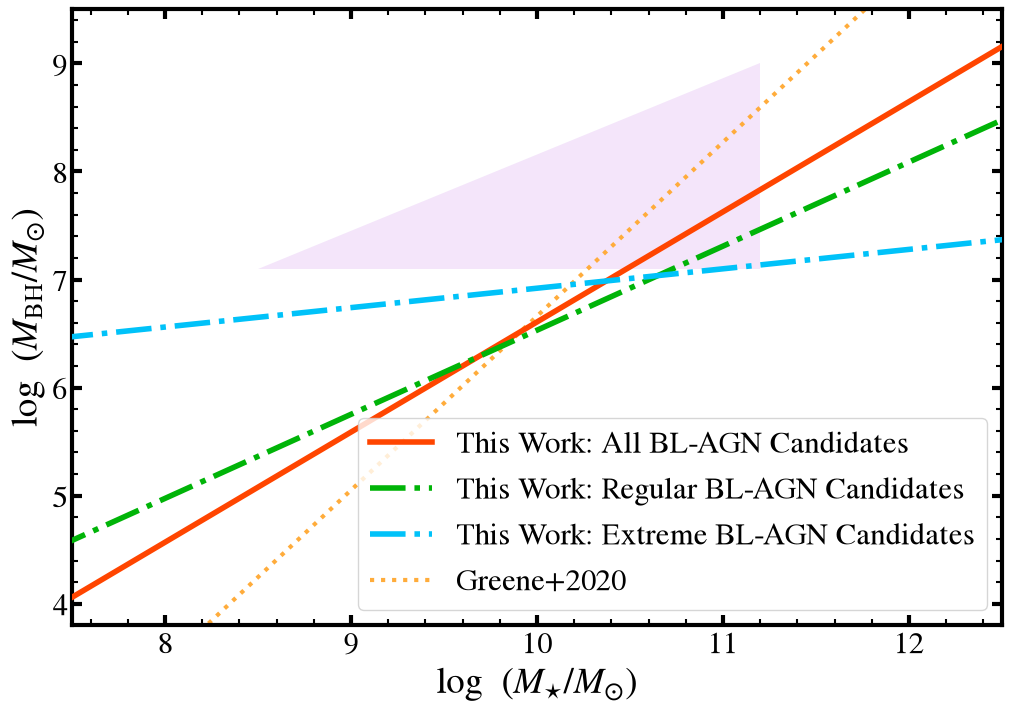

In [45]:
plt.figure(figsize = (12, 8))

x_coords = [8.5, 11.2, 11.2]
y_coords = [7.1, 7.1, 9]

# plt.hexbin(logmass[~is_psf], bh_mass[~is_psf], C = log_lamedd[~is_psf], \
#           gridsize = 50, vmin = -1.5, vmax = 1, cmap = 'PRGn')
plt.plot(np.log10(mass_xx), mbh_ext, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_ext, lw = 4.0, label = 'This Work: All BL-AGN Candidates', **ext_kwargs)
plt.plot(np.log10(mass_xx), mbh_extd, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_extd, lw = 4.0, label = 'This Work: Regular BL-AGN Candidates', **extd_kwargs)
plt.plot(np.log10(mass_xx), mbh_exte1, color = 'white', lw = 6.0, zorder = 1)
plt.plot(np.log10(mass_xx), mbh_exte1, lw = 4.0, label = 'This Work: Extreme BL-AGN Candidates', **exte_kwargs)
add_literature_fits(r13_early=False, suh20 = False, r13_late = False, \
                    pucha25 = False, greene20 = True, pacucci23 = False, label = True)
plt.fill(x_coords, y_coords, color = 'darkviolet', alpha = 0.1, edgecolor = 'none')
plt.gca().set(ylim = [3.8, 9.5], xlim = [7.5,12.5], xlabel = '$\log~(M_{\star}/M_{\odot})$',\
              ylabel = '$\log~(M_{\\rm BH}/M_{\odot})$')
plt.legend(loc = 'lower right')
# plt.savefig('mbh-mstar-panel.png')

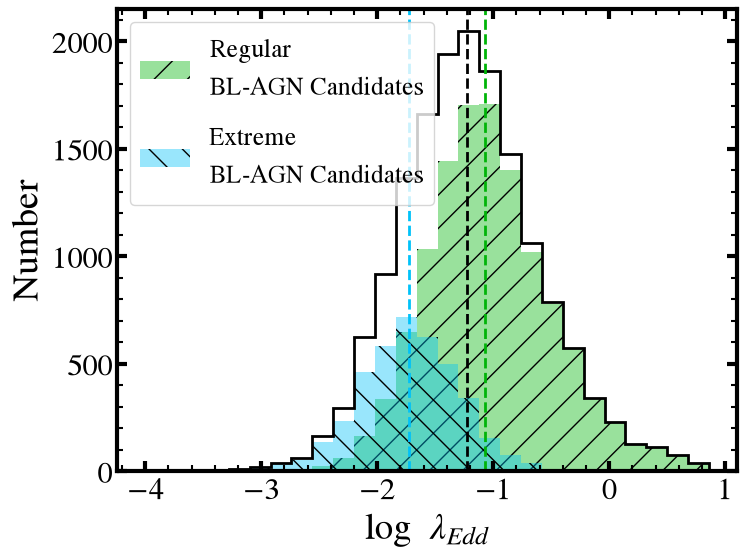

In [46]:
plt.figure(figsize = (8,6))
bins = np.arange(-4, 1, 0.18)

h1 = plt.hist(log_lamedd[~is_psf], bins = bins, histtype = 'step', color = 'k', lw = 2.0)
h2 = plt.hist(log_lamedd[~is_psf&is_def], bins = bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00b408', hatch = '/', label = 'Regular\nBL-AGN Candidates')
h3 = plt.hist(log_lamedd[~is_psf&is_ebl], bins = bins, histtype = 'bar', lw = 2.0, alpha = 0.4, color = '#00c2f9', hatch = '\\', label = 'Extreme\nBL-AGN Candidates')
plt.axvline(np.median(log_lamedd[~is_psf]), color = 'k', lw = 2.0, ls = '--')
plt.axvline(np.median(log_lamedd[~is_psf&is_def]), color = '#00b408', lw = 2.0, ls = '--')
plt.axvline(np.median(log_lamedd[~is_psf&is_ebl]), color = '#00c2f9', lw = 2.0, ls = '--')
plt.xlabel('$\log~\lambda_{Edd}$')
plt.ylabel('Number')
plt.legend(loc = 'upper left', fontsize = 18)

# plt.savefig('lamedd_dist.png')

In [47]:
# t1 = Table()
# t1.add_column(Column(bins[0:-1], name = 'LOG_EDD_RATIO', dtype = np.float32))
# t1.add_column(Column(h1[0], name = 'NUM_ALL', dtype = np.int))
# t1.add_column(Column(h2[0], name = 'NUM_REG_BLAGN', dtype = np.int))
# t1.add_column(Column(h3[0], name = 'NUM_EXT_BLAGN', dtype = np.int))

# t1.write('../catalogs/paper_figures/Fig07_eddratio_hist.csv', format = 'csv', overwrite = True)

In [48]:
10**np.median(log_lamedd[~is_psf]), 10**np.median(log_lamedd[~is_psf&is_def]), 10**np.median(log_lamedd[~is_psf&is_ebl])

(np.float64(0.059326414154933914),
 np.float64(0.08504097518914659),
 np.float64(0.01896080473824816))

### Overmassive Black Holes

In [49]:
mbh_mstar = (10**bh_mass)/(10**logmass)

In [50]:
## Overmassive BHs from DESI
is_overmassive = (mbh_mstar >= 0.01)

In [51]:
len(t[is_overmassive])

680

In [52]:
## Numbers 

print ('Number of overmassive BL-AGN Candidates (Only Extended) - logmass <= 9.5: ', len(t[~is_psf&lomass&is_overmassive]), '/', len(t[~is_psf&lomass]), round(len(t[~is_psf&lomass&is_overmassive])*100/len(t[~is_psf&lomass]), 1), '%')
print ('Number of overmassive BL-AGN Candidates (Only PSF) - logmass <= 9.5: ', len(t[is_psf&lomass&is_overmassive]), '/', len(t[is_psf&lomass]), round(len(t[is_psf&lomass&is_overmassive])*100/len(t[is_psf&lomass]), 1), '%')
print ('Total Number of overmassive BL-AGN Candidates - logmass <= 9.5: ', len(t[lomass&is_overmassive]), '/', len(t[lomass]), round(len(t[lomass&is_overmassive])*100/len(t[lomass]), 1), '%')

print ('Number of overmassive BL-AGN Candidates (Only Extended) - logmass <= 10: ', len(t[~is_psf&(logmass <= 10)&is_overmassive]), '/', len(t[~is_psf&(logmass <= 10)]), round(len(t[~is_psf&(logmass <= 10)&is_overmassive])*100/len(t[~is_psf&(logmass <= 10)]), 1), '%')
print ('Number of overmassive BL-AGN Candidates (Only PSF) - logmass <= 10: ', len(t[is_psf&(logmass <= 10)&is_overmassive]), '/', len(t[is_psf&(logmass <= 10)]), round(len(t[is_psf&(logmass <= 10)&is_overmassive])*100/len(t[is_psf&(logmass <= 10)]), 1), '%')
print ('Total Number of overmassive BL-AGN Candidates - logmass <= 10: ', len(t[(logmass <= 10)&is_overmassive]), '/', len(t[(logmass <= 10)]), round(len(t[(logmass <= 10)&is_overmassive])*100/len(t[(logmass <= 10)]), 1), '%')

Number of overmassive BL-AGN Candidates (Only Extended) - logmass <= 9.5:  2 / 276 0.7 %
Number of overmassive BL-AGN Candidates (Only PSF) - logmass <= 9.5:  27 / 158 17.1 %
Total Number of overmassive BL-AGN Candidates - logmass <= 9.5:  29 / 434 6.7 %
Number of overmassive BL-AGN Candidates (Only Extended) - logmass <= 10:  67 / 1583 4.2 %
Number of overmassive BL-AGN Candidates (Only PSF) - logmass <= 10:  232 / 883 26.3 %
Total Number of overmassive BL-AGN Candidates - logmass <= 10:  299 / 2466 12.1 %


In [53]:
mbins = np.arange(7.5, 13, 0.5)
om_frac_ext = np.array([])
om_frac_psf = np.array([])
om_frac_all = np.array([])

for m in mbins[:-1]: 
    msel = (logmass > 7)&(logmass < m+0.5)
    n_om_ext = len(logmass[msel&is_overmassive&~is_psf])
    n_om_psf = len(logmass[msel&is_overmassive&is_psf])
    n_ext = len(logmass[~is_psf&msel])
    n_psf = len(logmass[is_psf&msel])

    print (m+0.5, n_om_ext*100/n_ext)
    
    om_frac_ext = np.append(om_frac_ext, n_om_ext/n_ext)
    om_frac_psf = np.append(om_frac_psf, n_om_psf/n_psf)
    om_frac_all = np.append(om_frac_all, (n_om_ext+n_om_psf)/(n_ext+n_psf))

8.0 0.0
8.5 0.0
9.0 0.0
9.5 0.7246376811594203
10.0 4.232469993682881
10.5 2.80089628681178
11.0 1.393961982855013
11.5 1.1942776855281645
12.0 1.1792899035126443
12.5 1.1782496377039884


Text(0, 0.5, 'Cumulative Overmassive Fraction')

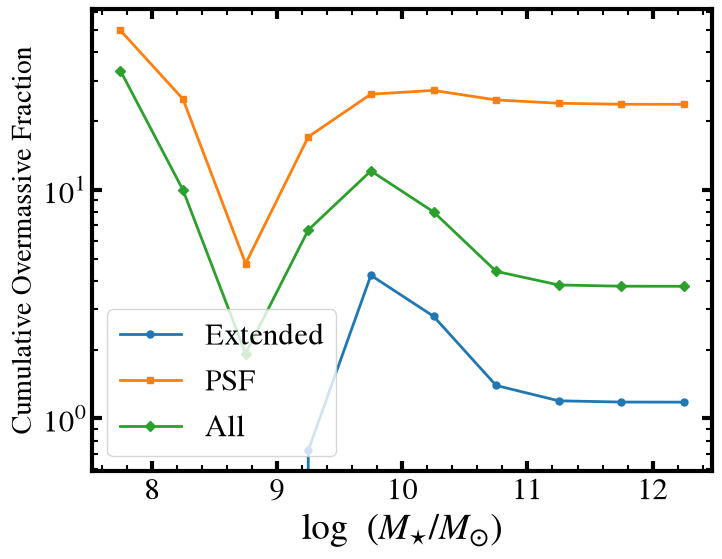

In [54]:
plt.figure(figsize = (8,6))
plt.plot(mbins[:-1]+0.25, om_frac_ext*100, marker = 'o', lw = 2.0, label = 'Extended')
plt.plot(mbins[:-1]+0.25, om_frac_psf*100, marker = 's', lw = 2.0, label = 'PSF')
plt.plot(mbins[:-1]+0.25, om_frac_all*100, marker = 'D', lw = 2.0, label = 'All')
plt.yscale('log')
plt.legend()
plt.xlabel('$\log~(M_{\star}/M_{\odot})$')
plt.ylabel('Cumulative Overmassive Fraction', fontsize = 20)

---